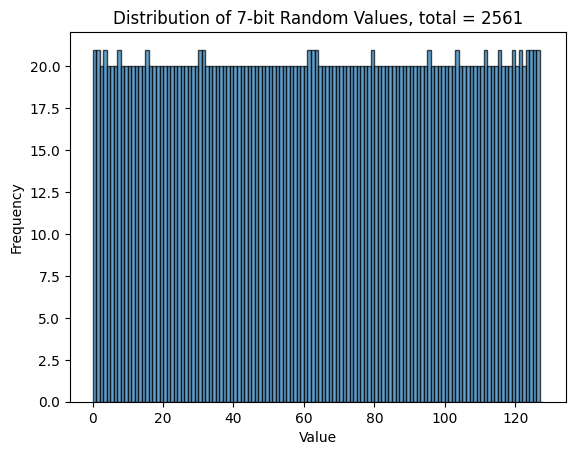

In [22]:
import matplotlib.pyplot as plt 
import numpy as np 
import re
import os 

path = os.path.join("..", "hw_impl.sim", "sim_1", "behav", "xsim", "LFSR_tb_monitor.txt")


values = []

with open(path, "r") as f:
    data = f.readlines()
    
    for line in data:
        line = line.strip()
        match = re.search(r'time=(\d+)', line)

        time_value = None
        if match is not None:
            time_value = int(match.group(1))  
        
        match = re.search(r"LFSR_out=(\d+)", line)
            
        LFSR_out = None    
        if match is not None:
            LFSR_out = int(match.group(1))
            values.append(LFSR_out)
        


# 1. Visualize distribution with a histogram
plt.hist(values, bins=range(0, 129), edgecolor='black', alpha=0.7)
plt.title(f"Distribution of 7-bit Random Values, total = {len(values)}")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

Shannon Entropy: 6.9884 bits
Chi-Square Statistic: 21.0414
p-value: 1.0000


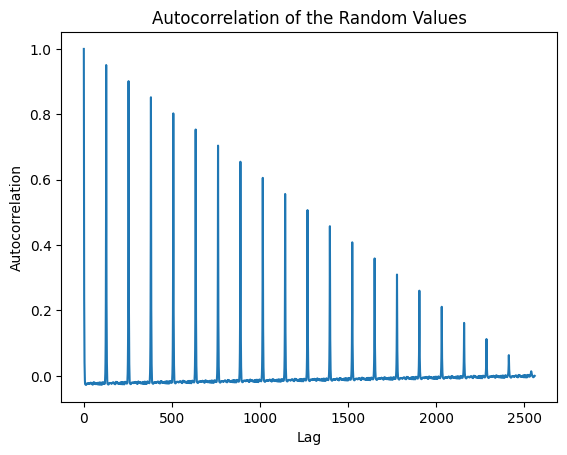

In [23]:
from scipy.stats import entropy, chisquare

# 2. Calculate Shannon entropy
# Probability distribution of each value in the range [0, 127]
value_counts = np.bincount(values, minlength=128)
probabilities = value_counts / len(values)

# Shannon entropy in bits
shannon_entropy = entropy(probabilities, base=2)
print(f"Shannon Entropy: {shannon_entropy:.4f} bits")

# 3. Perform a chi-square test to compare observed and expected frequencies
expected = np.full(128, len(values) / 128)  # Expected uniform distribution
chi2_stat, p_value = chisquare(value_counts, expected)

print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"p-value: {p_value:.4f}")

# 4. Calculate autocorrelation to check for patterns
autocorr = np.correlate(values - np.mean(values), values - np.mean(values), mode='full')
autocorr = autocorr[autocorr.size // 2:]  # Use only the positive lags

plt.plot(autocorr / autocorr[0])
plt.title("Autocorrelation of the Random Values")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.show()
